# Synthetic structure comparison: IMSTE and UMAP

This notebook compares 2D embeddings on three synthetic datasets designed to expose global layout differences: an unequal-gap chain of clusters, a branched hierarchy, and a spiral manifold. Each generator returns high-dimensional features plus a known 2D latent layout. The latent coordinates and group labels are used only for evaluation and plotting; neither method receives them.

The main global-layout summary is **latent distance rank correlation**: whether pairs that are nearer or farther in the known layout tend to stay nearer or farther in the embedding. **Trustworthiness** separately measures whether nearby points in the embedding were also nearby in the input features. These metrics describe different properties.

IMSTE uses 1,000 epochs in every fit. We also vary UMAP's `n_neighbors` and repeat both methods across seeds on fixed input data. These are targeted synthetic examples, not a general benchmark; the results should be read as evidence about these structures and settings.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from sklearn.manifold import trustworthiness
from sklearn.preprocessing import StandardScaler
from umap import UMAP

from imste import IteratedMinimumSpanningTreeEmbedder

RANDOM_STATE = 42
N_SAMPLES = 450
N_FEATURES = 32


In [2]:
def _high_dimensionalize(latent, rng, n_features=N_FEATURES, noise=0.04):
    """Mix a 2D latent layout into a higher-dimensional, mildly nonlinear space."""
    latent = np.asarray(latent, dtype=float)
    projection = rng.normal(size=(2, n_features))
    projection /= np.linalg.norm(projection, axis=1, keepdims=True)
    linear = latent @ projection
    nonlinear = 0.20 * np.sin(latent[:, :1] * 1.7 + 0.4) @ rng.normal(size=(1, n_features))
    nuisance = rng.normal(scale=noise, size=(len(latent), n_features))
    return linear + nonlinear + nuisance


def make_unequal_gap_chain(n=N_SAMPLES, seed=RANDOM_STATE):
    """Six unevenly populated clusters in a line with strongly unequal gaps."""
    rng = np.random.default_rng(seed + 5)
    counts = np.array([160, 35, 100, 25, 90, 40])
    counts[-1] += n - counts.sum()
    centers = np.array([-12.0, -5.0, -3.0, 2.0, 3.0, 12.0])
    clouds = [
        np.column_stack([rng.normal(center, 0.28, count), rng.normal(0, 0.15, count)])
        for center, count in zip(centers, counts)
    ]
    latent = np.vstack(clouds)
    labels = np.concatenate([np.full(count, i, dtype=int) for i, count in enumerate(counts)])
    order = rng.permutation(n)
    latent, labels = latent[order], labels[order]
    return _high_dimensionalize(latent, rng), latent, labels


def make_branched_hierarchy(n=N_SAMPLES, seed=RANDOM_STATE):
    """Uneven leaf clusters arranged along three branches from a shared root."""
    rng = np.random.default_rng(seed + 7)
    centers = np.array([
        [0, 0], [-3, 3], [-5, 5], [-5, 1],
        [3, 3], [5, 5], [5, 1], [0, -4], [0, -7],
    ])
    counts = np.array([15, 25, 80, 30, 130, 25, 30, 65, 50])
    counts[-1] += n - counts.sum()
    clouds = [
        rng.normal(center, [0.12, 0.16], size=(count, 2))
        for center, count in zip(centers, counts)
    ]
    latent = np.vstack(clouds)
    labels = np.concatenate([np.full(count, i, dtype=int) for i, count in enumerate(counts)])
    order = rng.permutation(n)
    latent, labels = latent[order], labels[order]
    return _high_dimensionalize(latent, rng), latent, labels


def make_spiral(n=N_SAMPLES, seed=RANDOM_STATE):
    """A noisy two-dimensional spiral with samples ordered along its winding path."""
    rng = np.random.default_rng(seed + 9)
    t = np.linspace(0.3, 4 * np.pi, n)
    radius = np.linspace(0.2, 5.0, n)
    latent = np.column_stack([radius * np.cos(t), radius * np.sin(t)])
    latent += rng.normal(scale=0.025, size=latent.shape)
    labels = np.minimum(np.arange(n) // max(1, n // 6), 5)
    order = rng.permutation(n)
    latent, labels = latent[order], labels[order]
    return _high_dimensionalize(latent, rng), latent, labels


dataset_generators = {
    "Unequal-gap cluster chain": make_unequal_gap_chain,
    "Branched hierarchy": make_branched_hierarchy,
    "Spiral manifold": make_spiral,
}


## Fit both methods

Inputs are standardized once per dataset, then passed identically to IMSTE and UMAP. Both methods produce two coordinates. IMSTE uses 5 MSTs and 1,000 optimization epochs. The main UMAP comparison uses `n_neighbors=20`; a later sweep checks 8, 20, and 50.

In [3]:
def _pairwise_latent_rank_correlation(latent, embedding, seed=RANDOM_STATE, n_pairs=12000):
    rng = np.random.default_rng(seed)
    i = rng.integers(0, len(latent), size=n_pairs)
    j = rng.integers(0, len(latent), size=n_pairs)
    valid = i != j
    i, j = i[valid], j[valid]
    latent_dist = np.linalg.norm(latent[i] - latent[j], axis=1)
    embedded_dist = np.linalg.norm(embedding[i] - embedding[j], axis=1)
    return float(spearmanr(latent_dist, embedded_dist).statistic)


def _make_reducer(method, seed=RANDOM_STATE, n_neighbors=20):
    if method == "IMSTE":
        return IteratedMinimumSpanningTreeEmbedder(
            n_components=2,
            n_msts=5,
            n_epochs=1000,
            mst_method="famst",
            mst_neighbors=12,
            random_state=seed,
            device="cpu",
        )
    if method == "UMAP":
        return UMAP(
            n_components=2,
            n_neighbors=n_neighbors,
            min_dist=0.1,
            metric="euclidean",
            random_state=seed,
            n_jobs=1,
        )
    raise ValueError(f"Unknown method: {method}")


def fit_comparison(X, latent, *, seed=RANDOM_STATE):
    X_scaled = StandardScaler().fit_transform(X)
    results = {}
    for method in ("IMSTE", "UMAP"):
        reducer = _make_reducer(method, seed=seed)
        embedding = reducer.fit_transform(X_scaled)
        results[method] = {
            "embedding": embedding,
            "trustworthiness@10": trustworthiness(X_scaled, embedding, n_neighbors=10),
            "latent distance rho": _pairwise_latent_rank_correlation(latent, embedding, seed=seed),
        }
        print(f"{method}: finished")
    return results


runs = {}
for dataset_name, generator in dataset_generators.items():
    print(f"Fitting {dataset_name} ...")
    X, latent, labels = generator()
    runs[dataset_name] = {
        "X": X,
        "latent": latent,
        "labels": labels,
        "methods": fit_comparison(X, latent),
    }


Fitting Unequal-gap cluster chain ...
IMSTE: finished
UMAP: finished
Fitting Branched hierarchy ...
IMSTE: finished
UMAP: finished
Fitting Spiral manifold ...
IMSTE: finished
UMAP: finished


## Inspect the embeddings

Latent panels show the structure used to generate each dataset. The method panels use the same label colors, but their axes, rotations, reflections, and scale are arbitrary.

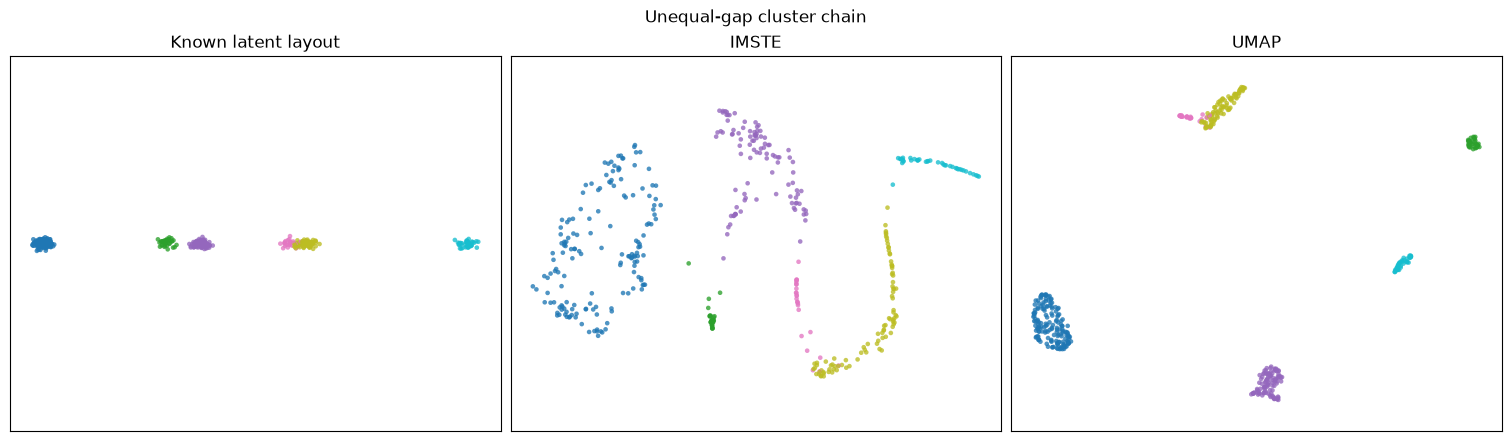

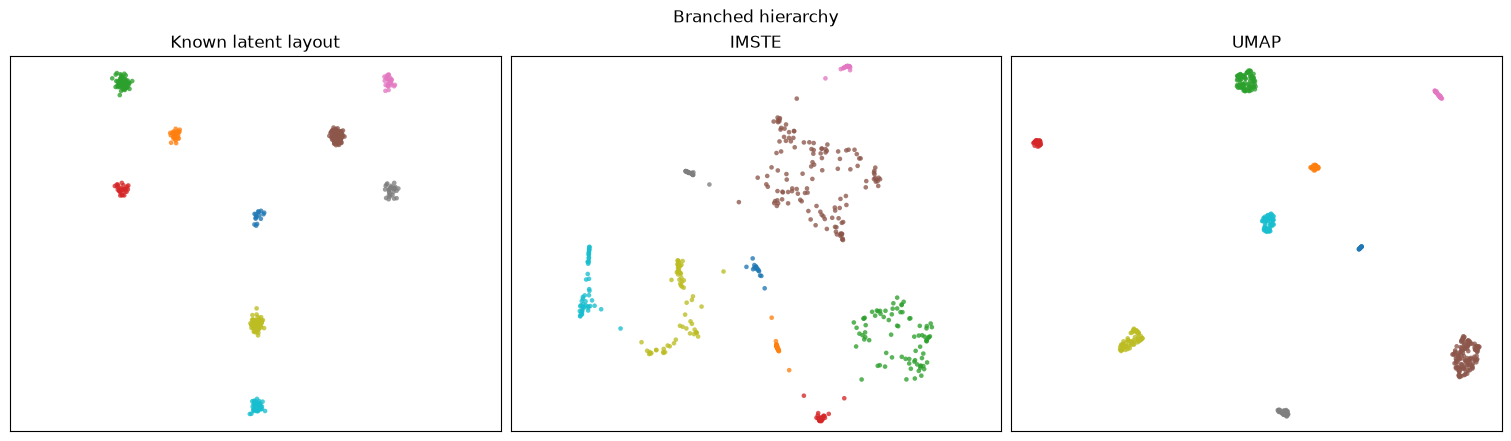

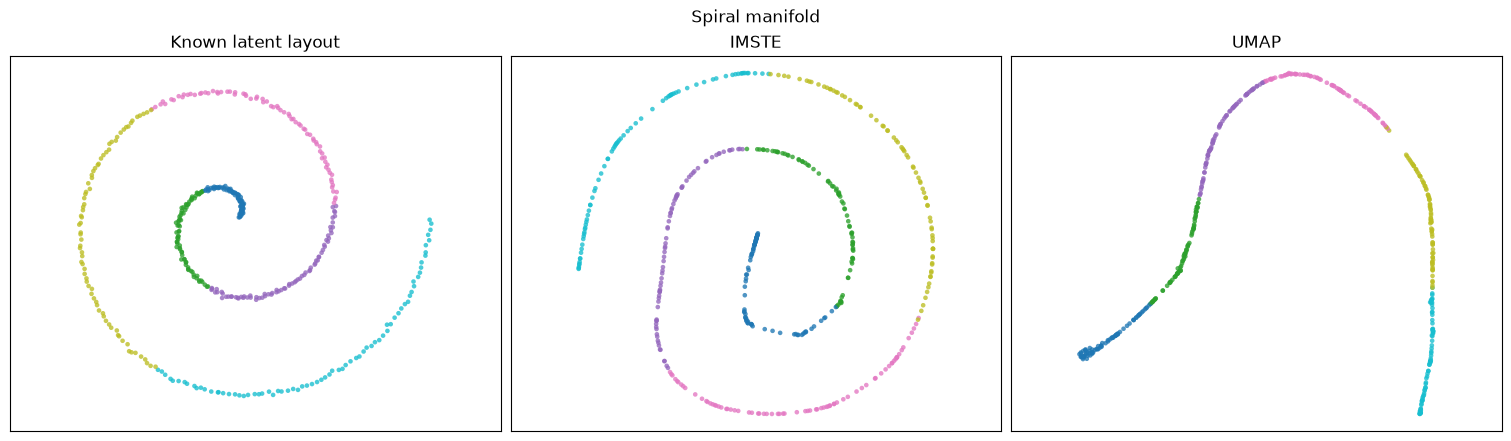

In [4]:
palette = "tab10"
for dataset_name, run in runs.items():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
    panels = [(run["latent"], "Known latent layout")]
    panels.extend((run["methods"][method]["embedding"], method) for method in ("IMSTE", "UMAP"))
    for ax, (coordinates, title) in zip(axes, panels):
        points = ax.scatter(coordinates[:, 0], coordinates[:, 1], c=run["labels"],
                            cmap=palette, s=11, alpha=0.78, linewidths=0)
        ax.set_title(title)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_aspect("equal", adjustable="datalim")
    fig.suptitle(dataset_name)
    plt.show()



## Compare the summary measures

Interpret local trustworthiness and global latent-distance ordering separately. A higher score on one does not imply that the embedding is better for every purpose.

In [5]:
rows = []
for dataset_name, run in runs.items():
    for method, result in run["methods"].items():
        rows.append({"dataset": dataset_name, "method": method,
                     "trustworthiness@10": result["trustworthiness@10"],
                     "latent distance rho": result["latent distance rho"]})
summary = pd.DataFrame(rows)
summary


,dataset,method,trustworthiness@10,latent distance rho
0,Unequal-gap cluster chain,IMSTE,0.973295,0.841564
1,Unequal-gap cluster chain,UMAP,0.976137,0.526311
2,Branched hierarchy,IMSTE,0.977808,0.878510
3,Branched hierarchy,UMAP,0.981473,0.505881
4,Spiral manifold,IMSTE,0.998562,0.919198
5,Spiral manifold,UMAP,0.998629,0.391120


The seed check below keeps each dataset fixed and changes the methods' random seeds. This helps distinguish a repeatable geometry effect from one favorable initialization.

## Check robustness across seeds

This repeats both methods on the same generated input data while varying only the embedding seed. IMSTE uses 1,000 epochs for every repeat. The latent-distance correlations indicate whether the observed global-layout difference persists across initializations.

In [6]:
seed_rows = []
for dataset_name, run in runs.items():
    X_scaled = StandardScaler().fit_transform(run["X"])
    for seed in (7, 123):  # seed 42 is already included in the main comparison
        for method in ("IMSTE", "UMAP"):
            embedding = _make_reducer(method, seed=seed).fit_transform(X_scaled)
            seed_rows.append({
                "dataset": dataset_name,
                "seed": seed,
                "method": method,
                "latent distance rho": _pairwise_latent_rank_correlation(
                    run["latent"], embedding, seed=seed
                ),
            })
seed_robustness = pd.DataFrame(seed_rows)
seed_robustness


,dataset,seed,method,latent distance rho
0,Unequal-gap cluster chain,7,IMSTE,0.837195
1,Unequal-gap cluster chain,7,UMAP,0.373106
2,Unequal-gap cluster chain,123,IMSTE,0.829094
3,Unequal-gap cluster chain,123,UMAP,0.537986
4,Branched hierarchy,7,IMSTE,0.884408
5,Branched hierarchy,7,UMAP,0.534612
6,Branched hierarchy,123,IMSTE,0.884772
7,Branched hierarchy,123,UMAP,0.482709
8,Spiral manifold,7,IMSTE,0.919211
9,Spiral manifold,7,UMAP,0.280403


## Sensitivity to UMAP neighborhood size

UMAP's neighborhood size can affect its global layout. The sweep below compares `n_neighbors` 8, 20, and 50 for each fixed dataset.

In [7]:
sensitivity_rows = []
for dataset_name, run in runs.items():
    X_scaled = StandardScaler().fit_transform(run["X"])
    for neighbors in (8, 20, 50):
        embedding = _make_reducer("UMAP", n_neighbors=neighbors).fit_transform(X_scaled)
        sensitivity_rows.append({
            "dataset": dataset_name,
            "n_neighbors": neighbors,
            "trustworthiness@10": trustworthiness(X_scaled, embedding, n_neighbors=10),
            "latent distance rho": _pairwise_latent_rank_correlation(
                run["latent"], embedding, seed=RANDOM_STATE
            ),
        })
umap_sensitivity = pd.DataFrame(sensitivity_rows)
umap_sensitivity


,dataset,n_neighbors,trustworthiness@10,latent distance rho
0,Unequal-gap cluster chain,8,0.979250,0.439539
1,Unequal-gap cluster chain,20,0.976137,0.526311
2,Unequal-gap cluster chain,50,0.975401,0.655010
3,Branched hierarchy,8,0.982695,0.529827
4,Branched hierarchy,20,0.981473,0.505881
5,Branched hierarchy,50,0.979135,0.606917
6,Spiral manifold,8,0.998295,0.388544
7,Spiral manifold,20,0.998629,0.391120
8,Spiral manifold,50,0.998538,0.333096


## Reading the results

Look for persistent differences in latent-distance correlation across seeds and UMAP neighborhood sizes. Trustworthiness captures local neighborhood fidelity and may favor a different method. These generators intentionally emphasize global branch order, unequal cluster gaps, and winding structure. They do not establish that one method is generally superior.

## Why IMSTE may help with biological data

### What these synthetic results suggest

In these examples, the latent structures have meaningful global organization: unequal gaps between groups, branches that share a root, and a winding trajectory. IMSTE's graph explicitly connects the samples through ranked minimum spanning trees. The first tree supplies a short global scaffold; later trees add alternative connections, with lower attraction weight for higher-ranked edges. This gives the optimizer relationships that span beyond only the closest local neighbors. In this run, that construction corresponds to higher correlation with the known global layout than UMAP across the tested neighborhood sizes and seeds. UMAP retains slightly higher local trustworthiness, so the result points to a difference in emphasis rather than an overall quality ranking.

### Biological hypothesis

A dataset of cells, organisms, or samples may have a similar structure when it contains continuous transitions, rare intermediate states, uneven sampling density, and branching developmental or ecological trajectories. In such cases, a ranked tree scaffold could help an embedding keep broad paths and branch relationships visible even when some regions are sparsely sampled. IMSTE may therefore be useful when the question concerns global ordering or connectivity across a population, while a local-neighborhood view remains important for inspecting fine cell-state neighborhoods.

This is a hypothesis motivated by controlled synthetic examples, not evidence that IMSTE is generally better for biological data. The benefit depends on whether the chosen features, preprocessing, and distance metric make the MST edges biologically meaningful. Noise, batch effects, or inappropriate scaling can create misleading bridges, and global distance correlation alone does not validate a biological trajectory.

### How to test the hypothesis biologically

Compare IMSTE and UMAP on the same normalized feature matrix across multiple seeds and parameter settings. Evaluate local neighborhood preservation separately from global trajectory or lineage structure. Where available, use independent evidence such as time points, lineage tracing, perturbation responses, known marker gradients, or held-out labels to test whether inferred paths and branches match biology. Check that conclusions persist under resampling and reasonable preprocessing choices.